In [14]:
import os
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader
from PIL import Image

# Project paths
PROJECT_ROOT = r"D:\VisionInspect-AI"

MANIFEST_PATH = os.path.join(
    PROJECT_ROOT, "outputs", "manifests", "bottle_custom_split.csv"
)

MODEL_PATH = os.path.join(
    PROJECT_ROOT, "models", "bottle_unet_corrected_best.pth"
)

OUTPUT_DIR = os.path.join(
    PROJECT_ROOT, "outputs", "bottle_unet_corrected", "test_evaluation"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Configuration
IMAGE_SIZE = 256
BATCH_SIZE = 4
THRESHOLD = 0.5

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)
print("Checkpoint exists:", os.path.exists(MODEL_PATH))
print("Manifest exists:", os.path.exists(MANIFEST_PATH))
import os
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt

PROJECT_ROOT = r"D:\VisionInspect-AI"

MANIFEST_PATH = os.path.join(
    PROJECT_ROOT,
    "outputs",
    "manifests",
    "bottle_custom_split.csv"
)

df = pd.read_csv(MANIFEST_PATH)

print("Manifest loaded successfully!")
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())


Device: cuda
Checkpoint exists: True
Manifest exists: True
Manifest loaded successfully!
Dataset shape: (292, 6)
Columns: ['image_path', 'mask_path', 'category', 'defect_type', 'is_anomaly', 'project_split']


In [15]:
# Select only the held-out test images
test_df = df[df["project_split"] == "test"].copy()

print("Total test images:", len(test_df))

print("\nNormal vs Defective:")
print(test_df["is_anomaly"].value_counts())

print("\nDefect distribution:")
print(test_df["defect_type"].value_counts())

print("\nTest split verification:")
print(test_df["project_split"].value_counts())

Total test images: 32

Normal vs Defective:
is_anomaly
0    20
1    12
Name: count, dtype: int64

Defect distribution:
defect_type
good             20
broken_large      4
broken_small      4
contamination     4
Name: count, dtype: int64

Test split verification:
project_split
test    32
Name: count, dtype: int64


In [16]:
class BottleTestDataset(Dataset):
    def __init__(self, dataframe, image_size=256):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_size = image_size

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]

        # Load and resize image
        image = Image.open(row["image_path"]).convert("RGB")
        image = image.resize(
            (self.image_size, self.image_size),
            Image.Resampling.BILINEAR
        )

        image = np.array(image, dtype=np.float32) / 255.0
        image = torch.from_numpy(image).permute(2, 0, 1)

        # Load ground-truth mask
        if pd.isna(row["mask_path"]):
            mask = np.zeros(
                (self.image_size, self.image_size),
                dtype=np.float32
            )
        else:
            mask = Image.open(row["mask_path"]).convert("L")
            mask = mask.resize(
                (self.image_size, self.image_size),
                Image.Resampling.NEAREST
            )
            mask = np.array(mask, dtype=np.float32)
            mask = (mask > 0).astype(np.float32)

        mask = torch.from_numpy(mask).unsqueeze(0)

        return image, mask, int(row["is_anomaly"]), row["defect_type"]


test_dataset = BottleTestDataset(test_df, IMAGE_SIZE)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Test dataset created:", len(test_dataset))
print("Test batches:", len(test_loader))

# Verify one batch
images, masks, labels, defect_types = next(iter(test_loader))

print("Image shape:", images.shape)
print("Mask shape:", masks.shape)
print("Labels:", labels)
print("Defect types:", defect_types)

Test dataset created: 32
Test batches: 8
Image shape: torch.Size([4, 3, 256, 256])
Mask shape: torch.Size([4, 1, 256, 256])
Labels: tensor([0, 0, 0, 0])
Defect types: ('good', 'good', 'good', 'good')


In [17]:
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.pool = nn.MaxPool2d(2)

        self.enc1 = DoubleConv(3, 32)
        self.enc2 = DoubleConv(32, 64)
        self.enc3 = DoubleConv(64, 128)
        self.enc4 = DoubleConv(128, 256)

        self.bottleneck = DoubleConv(256, 512)

        self.up4 = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.dec4 = DoubleConv(512, 256)

        self.up3 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec3 = DoubleConv(256, 128)

        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec2 = DoubleConv(128, 64)

        self.up1 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec1 = DoubleConv(64, 32)

        self.output = nn.Conv2d(32, 1, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = self.dec4(torch.cat([self.up4(b), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))

        return self.output(d1)

In [ ]:
model = UNet().to(DEVICE)

checkpoint = torch.load(
    MODEL_PATH,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("U-Net checkpoint loaded successfully!")
print("Device:", DEVICE)
print("Parameters:", sum(p.numel() for p in model.parameters()))


U-Net checkpoint loaded successfully!
Device: cuda
Parameters: 7765985


In [ ]:
all_predictions = []
all_masks = []
all_labels = []
all_defect_types = []

with torch.no_grad():
    for images, masks, labels, defect_types in test_loader:

        images = images.to(DEVICE)

        # Model produces raw logits
        logits = model(images)

        # Convert logits into probabilities
        probabilities = torch.sigmoid(logits)

        # Apply threshold to create binary masks
        predictions = (probabilities >= THRESHOLD).float()

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_masks.extend(masks.numpy())

        all_labels.extend(labels.numpy())

        all_defect_types.extend(defect_types)


all_predictions = np.array(all_predictions)
all_masks = np.array(all_masks)
all_labels = np.array(all_labels)

print("Inference completed!")
print("Predictions shape:", all_predictions.shape)
print("Ground truth shape:", all_masks.shape)
print("Labels shape:", all_labels.shape)

Inference completed!
Predictions shape: (32, 1, 256, 256)
Ground truth shape: (32, 1, 256, 256)
Labels shape: (32,)


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

# Flatten masks and predictions
pred_flat = all_predictions.flatten()
true_flat = all_masks.flatten()

# Pixel-level metrics
tp = np.sum((pred_flat == 1) & (true_flat == 1))
fp = np.sum((pred_flat == 1) & (true_flat == 0))
fn = np.sum((pred_flat == 0) & (true_flat == 1))

dice = (2 * tp) / (2 * tp + fp + fn + 1e-8)
iou = tp / (tp + fp + fn + 1e-8)
precision = tp / (tp + fp + 1e-8)
recall = tp / (tp + fn + 1e-8)

# Normal-image false alarm rate
normal_indices = np.where(all_labels == 0)[0]

normal_false_alarms = sum(
    np.any(all_predictions[i] > 0)
    for i in normal_indices
)

normal_far = normal_false_alarms / len(normal_indices)

print("========== BOTTLE U-NET TEST RESULTS ==========")
print(f"Pixel Dice Score : {dice:.4f}")
print(f"Pixel IoU Score  : {iou:.4f}")
print(f"Pixel Precision  : {precision:.4f}")
print(f"Pixel Recall     : {recall:.4f}")
print(f"Normal FAR       : {normal_far:.2%}")
print(f"Normal false alarms: {normal_false_alarms}/{len(normal_indices)}")

========== BOTTLE U-NET TEST RESULTS ==========
Pixel Dice Score : 0.8949
Pixel IoU Score  : 0.8098
Pixel Precision  : 0.9246
Pixel Recall     : 0.8671
Normal FAR       : 0.00%
Normal false alarms: 0/20


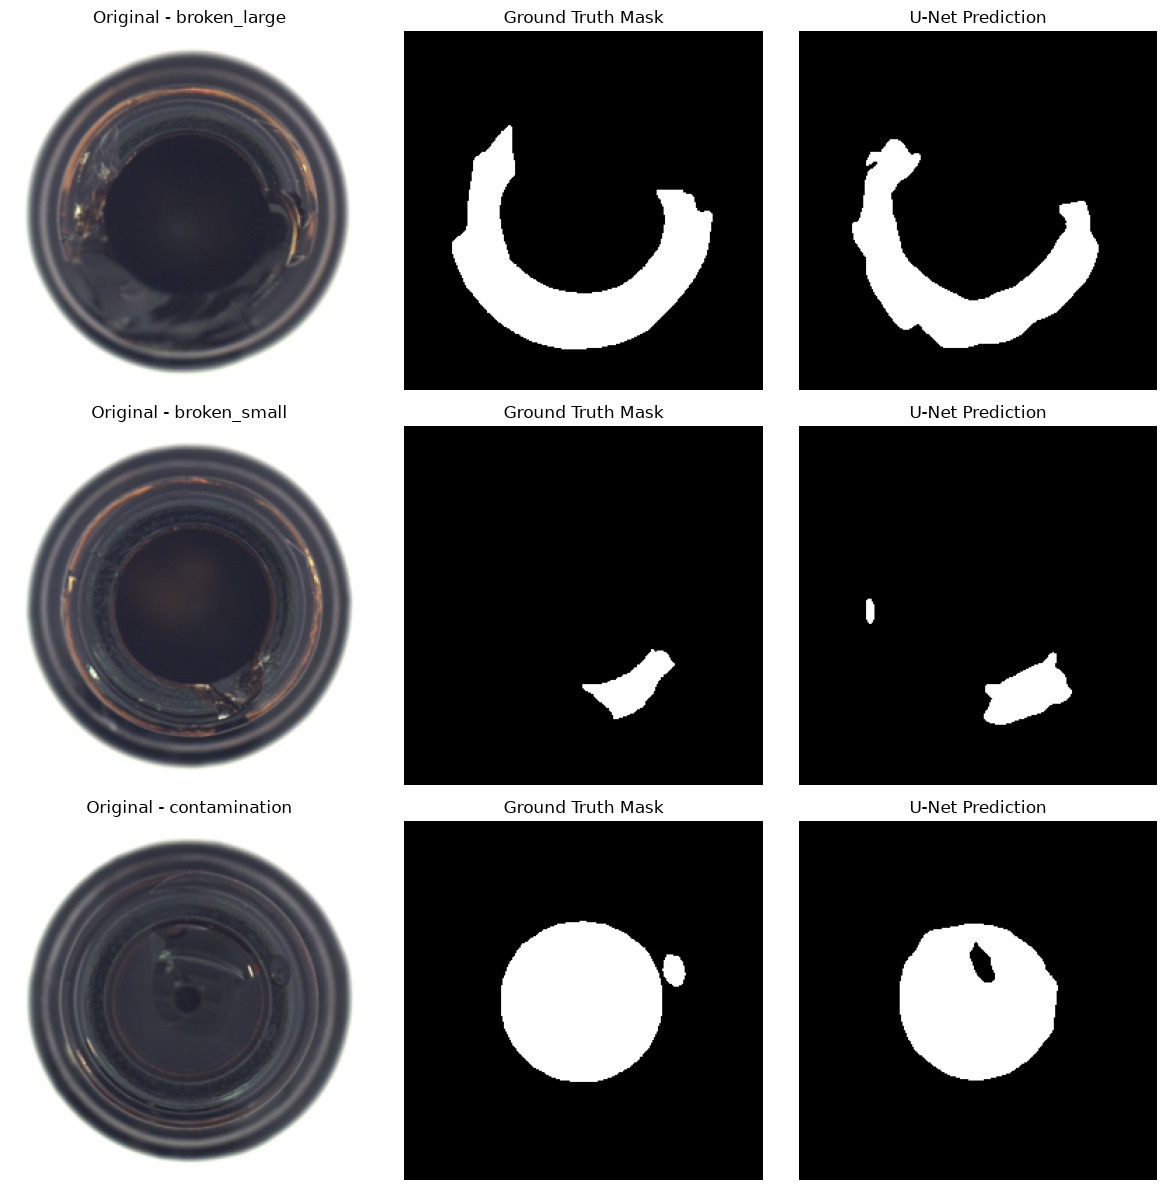

Visualization saved: D:\VisionInspect-AI\outputs\bottle_unet_corrected\test_evaluation\prediction_visualization.png


In [ ]:
import random

# Find defective test images
defect_indices = np.where(all_labels == 1)[0]

# Select one image from each defect category
selected_indices = []

for defect in ["broken_large", "broken_small", "contamination"]:
    candidates = [
        i for i in defect_indices
        if all_defect_types[i] == defect
    ]

    if candidates:
        selected_indices.append(candidates[0])

# Display original, actual mask and predicted mask
fig, axes = plt.subplots(
    len(selected_indices), 3,
    figsize=(12, 4 * len(selected_indices))
)

for row, idx in enumerate(selected_indices):

    image, actual_mask, _, defect_type = test_dataset[idx]

    original = image.permute(1, 2, 0).numpy()
    actual = actual_mask.squeeze().numpy()
    predicted = all_predictions[idx].squeeze()

    axes[row, 0].imshow(original)
    axes[row, 0].set_title(f"Original - {defect_type}")

    axes[row, 1].imshow(actual, cmap="gray")
    axes[row, 1].set_title("Ground Truth Mask")

    axes[row, 2].imshow(predicted, cmap="gray")
    axes[row, 2].set_title("U-Net Prediction")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()

save_path = os.path.join(OUTPUT_DIR, "prediction_visualization.png")
plt.savefig(save_path, dpi=150, bbox_inches="tight")
plt.show()

print("Visualization saved:", save_path)

In [ ]:
import json
import numpy as np
import pandas as pd
import os

results = {}

# Overall pixel-level metrics
tp = np.sum(all_predictions * all_masks)
fp = np.sum(all_predictions * (1 - all_masks))
fn = np.sum((1 - all_predictions) * all_masks)

results["overall"] = {
    "dice": float(2 * tp / (2 * tp + fp + fn + 1e-8)),
    "iou": float(tp / (tp + fp + fn + 1e-8)),
    "precision": float(tp / (tp + fp + 1e-8)),
    "recall": float(tp / (tp + fn + 1e-8))
}

# Per-defect metrics
results["per_defect"] = {}

for defect in ["broken_large", "broken_small", "contamination"]:
    indices = [
        i for i, name in enumerate(all_defect_types)
        if name == defect
    ]

    pred = all_predictions[indices]
    truth = all_masks[indices]

    tp_d = np.sum(pred * truth)
    fp_d = np.sum(pred * (1 - truth))
    fn_d = np.sum((1 - pred) * truth)

    results["per_defect"][defect] = {
        "images": len(indices),
        "dice": float(2 * tp_d / (2 * tp_d + fp_d + fn_d + 1e-8)),
        "iou": float(tp_d / (tp_d + fp_d + fn_d + 1e-8)),
        "precision": float(tp_d / (tp_d + fp_d + 1e-8)),
        "recall": float(tp_d / (tp_d + fn_d + 1e-8))
    }

# Normal image false alarm rate
normal_indices = np.where(all_labels == 0)[0]

normal_false_alarms = sum(
    np.any(all_predictions[i] > 0)
    for i in normal_indices
)

results["normal_images"] = {
    "total": len(normal_indices),
    "false_alarms": int(normal_false_alarms),
    "false_alarm_rate": float(normal_false_alarms / len(normal_indices))
}

# Image-level defect detection
detected_defects = sum(
    np.any(all_predictions[i] > 0)
    for i in np.where(all_labels == 1)[0]
)

defect_indices = np.where(all_labels == 1)[0]

results["image_detection"] = {
    "total_defective_images": len(defect_indices),
    "detected_defective_images": int(detected_defects),
    "detection_rate": float(detected_defects / len(defect_indices))
}

# Display report
print("========== COMPLETE BOTTLE U-NET TEST REPORT ==========")

print("\nOVERALL PIXEL METRICS")
for key, value in results["overall"].items():
    print(f"{key.upper():12}: {value:.4f}")

print("\nPER-DEFECT METRICS")
for defect, metrics in results["per_defect"].items():
    print(f"\n{defect.upper()} ({metrics['images']} images)")
    for key, value in metrics.items():
        if key != "images":
            print(f"{key.upper():12}: {value:.4f}")

print("\nNORMAL IMAGE CHECK")
print(results["normal_images"])

print("\nIMAGE-LEVEL DEFECT DETECTION")
print(results["image_detection"])

# Save report
report_path = os.path.join(OUTPUT_DIR, "complete_test_report.json")

with open(report_path, "w") as f:
    json.dump(results, f, indent=4)

print("\nReport saved:", report_path)

NameError: name 'all_predictions' is not defined